# CardioVision: exploratory analysis and cleaning

Convert cardio age to years, remove implausible blood-pressure records using the requested physiological bounds, impute Cleveland `ca`/`thal` missing values with their feature medians, then save target-group distribution and correlation plots under `result/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "data" / "cardio_train.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate data/cardio_train.csv from the notebook working directory.")
DATA_DIR = PROJECT_ROOT / "data"
RESULT_DIR = PROJECT_ROOT / "result"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

cleveland_columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
    "exang", "oldpeak", "slope", "ca", "thal", "target",
]
df_cardio = pd.read_csv(DATA_DIR / "cardio_train.csv", sep=";")
df_framingham = pd.read_csv(DATA_DIR / "framingham.csv")
df_cleveland = pd.read_csv(
    DATA_DIR / "UCI" / "processed.cleveland.data",
    header=None,
    names=cleveland_columns,
    na_values=["?"],
)
print("Loaded dataset shapes:", {
    "Cardio Train": df_cardio.shape,
    "Framingham": df_framingham.shape,
    "Cleveland": df_cleveland.shape,
})

Loaded dataset shapes: {'Cardio Train': (70000, 13), 'Framingham': (4240, 16), 'Cleveland': (303, 14)}


## Cleaning

Cardio blood-pressure records are retained only when systolic pressure is in `[50, 240]` and diastolic pressure is in `[30, 150]`. Cleveland missing predictors are median-imputed; target rows are preserved.

In [2]:
df_cardio["age_years"] = (df_cardio["age"] / 365.25).astype(int)
invalid_systolic = ~df_cardio["ap_hi"].between(50, 240, inclusive="both")
invalid_diastolic = ~df_cardio["ap_lo"].between(30, 150, inclusive="both")
invalid_bp = invalid_systolic | invalid_diastolic
bp_quality = {
    "invalid systolic rows": int(invalid_systolic.sum()),
    "invalid diastolic rows": int(invalid_diastolic.sum()),
    "rows removed (either condition)": int(invalid_bp.sum()),
}
df_cardio_clean = df_cardio.loc[~invalid_bp].copy()

for column in ["ca", "thal"]:
    df_cleveland[column] = pd.to_numeric(df_cleveland[column].replace("?", np.nan), errors="coerce")
cleveland_missing_before = df_cleveland[["ca", "thal"]].isna().sum()
df_cleveland_clean = df_cleveland.copy()
for column in ["ca", "thal"]:
    median_value = df_cleveland_clean[column].median()
    if pd.isna(median_value):
        raise ValueError(f"Cannot impute {column}: no observed values are available.")
    df_cleveland_clean[column] = df_cleveland_clean[column].fillna(median_value)

print("Cardio blood-pressure quality checks:", bp_quality)
print(f"Cardio rows: {len(df_cardio):,} -> {len(df_cardio_clean):,}")
print("Cleveland missing ca/thal before imputation:")
display(cleveland_missing_before.to_frame("missing_before"))
print("Cleveland missing ca/thal after imputation:")
display(df_cleveland_clean[["ca", "thal"]].isna().sum().to_frame("missing_after"))
print("Median imputation values:", {
    column: float(df_cleveland[column].median()) for column in ["ca", "thal"]
})

Cardio blood-pressure quality checks: {'invalid systolic rows': 228, 'invalid diastolic rows': 1028, 'rows removed (either condition)': 1239}
Cardio rows: 70,000 -> 68,761
Cleveland missing ca/thal before imputation:


,missing_before
ca,4
thal,2


Cleveland missing ca/thal after imputation:


,missing_after
ca,0
thal,0


Median imputation values: {'ca': 0.0, 'thal': 3.0}


## Target-group distributions

Each dataset gets one three-panel figure: age, blood-pressure distributions (systolic and diastolic where available), and cholesterol. Cardio distributions use the cleaned, plausible-BP subset. Figures are saved at 300 DPI.

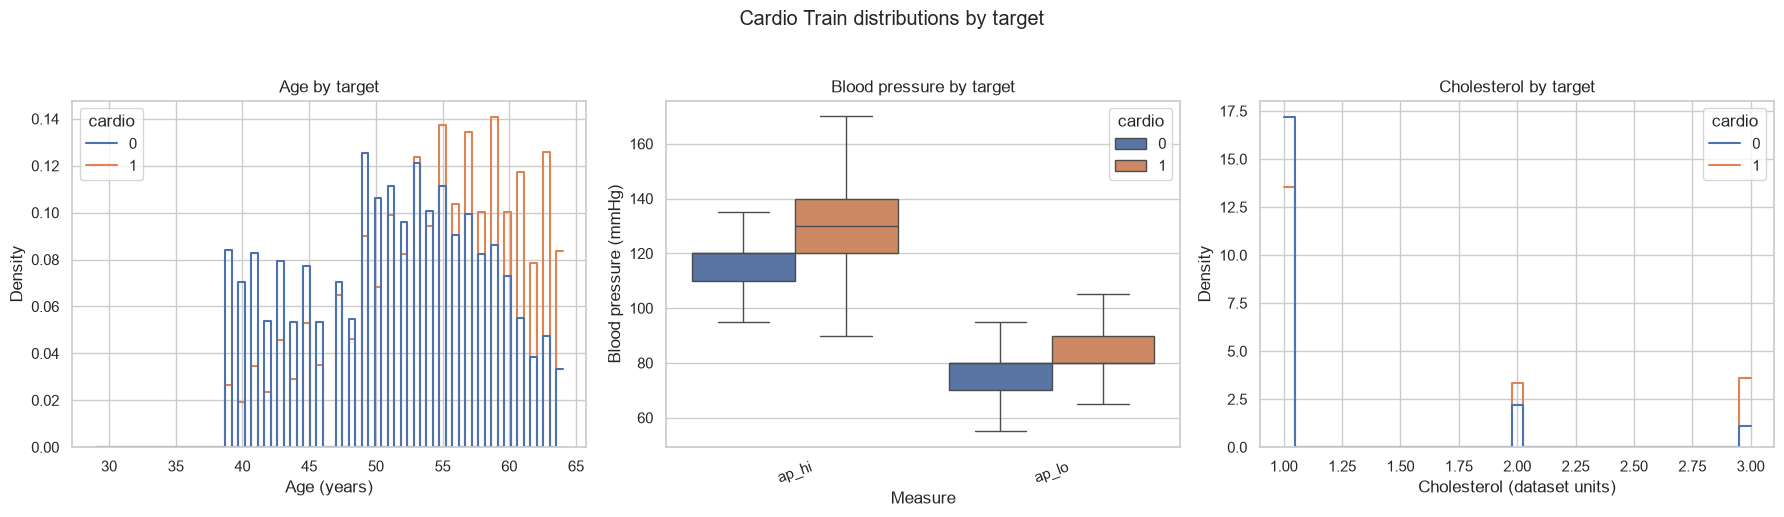

Saved C:\Users\kunug\OneDrive\Desktop\cardioVision\result\02_cardio_train_distributions.png


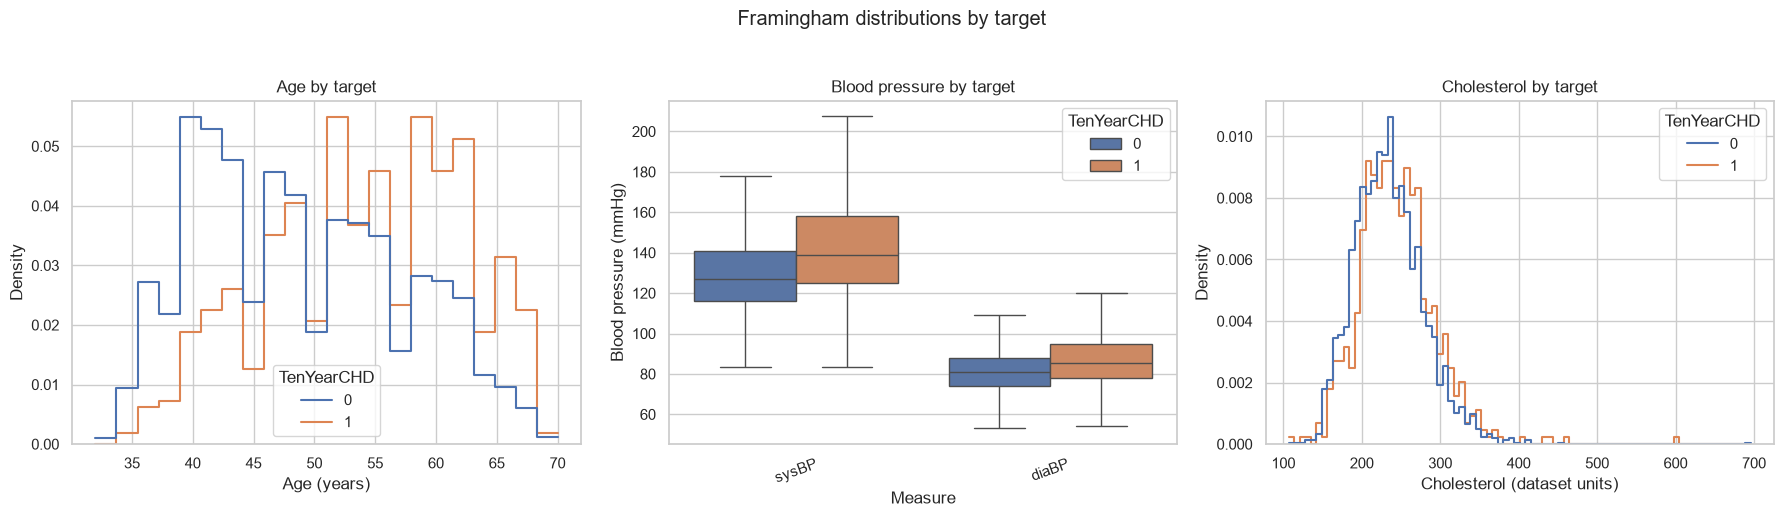

Saved C:\Users\kunug\OneDrive\Desktop\cardioVision\result\02_framingham_distributions.png


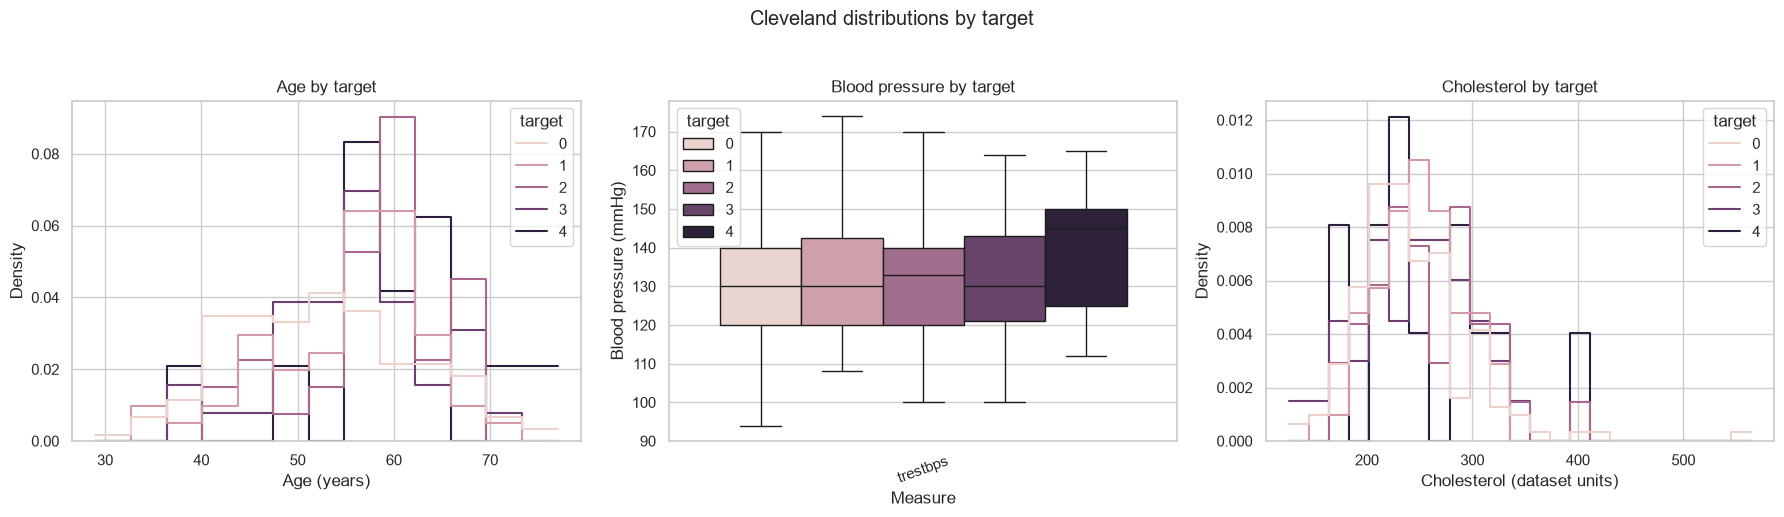

Saved C:\Users\kunug\OneDrive\Desktop\cardioVision\result\02_cleveland_distributions.png


In [3]:
plot_specs = [
    {
        "name": "cardio_train",
        "df": df_cardio_clean,
        "target": "cardio",
        "age": "age_years",
        "bp": ["ap_hi", "ap_lo"],
        "chol": "cholesterol",
    },
    {
        "name": "framingham",
        "df": df_framingham,
        "target": "TenYearCHD",
        "age": "age",
        "bp": ["sysBP", "diaBP"],
        "chol": "totChol",
    },
    {
        "name": "cleveland",
        "df": df_cleveland_clean,
        "target": "target",
        "age": "age",
        "bp": ["trestbps"],
        "chol": "chol",
    },
]

for spec in plot_specs:
    df = spec["df"]
    target = spec["target"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(
        data=df, x=spec["age"], hue=target, stat="density", common_norm=False,
        element="step", fill=False, ax=axes[0],
    )
    axes[0].set_title("Age by target")
    axes[0].set_xlabel("Age (years)")

    bp_long = df[[target, *spec["bp"]]].melt(
        id_vars=target, var_name="blood_pressure_measure", value_name="pressure"
    )
    sns.boxplot(
        data=bp_long, x="blood_pressure_measure", y="pressure", hue=target,
        showfliers=False, ax=axes[1],
    )
    axes[1].set_title("Blood pressure by target")
    axes[1].set_xlabel("Measure")
    axes[1].set_ylabel("Blood pressure (mmHg)")
    axes[1].tick_params(axis="x", rotation=20)

    sns.histplot(
        data=df, x=spec["chol"], hue=target, stat="density", common_norm=False,
        element="step", fill=False, ax=axes[2],
    )
    axes[2].set_title("Cholesterol by target")
    axes[2].set_xlabel("Cholesterol (dataset units)")
    fig.suptitle(f"{spec['name'].replace('_', ' ').title()} distributions by target", y=1.03)
    fig.tight_layout()
    output_path = RESULT_DIR / f"02_{spec['name']}_distributions.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved {output_path}")

## Numeric correlation heatmaps

Pairwise Pearson correlations are calculated over numeric columns; correlations involving encoded categorical variables should be interpreted cautiously.

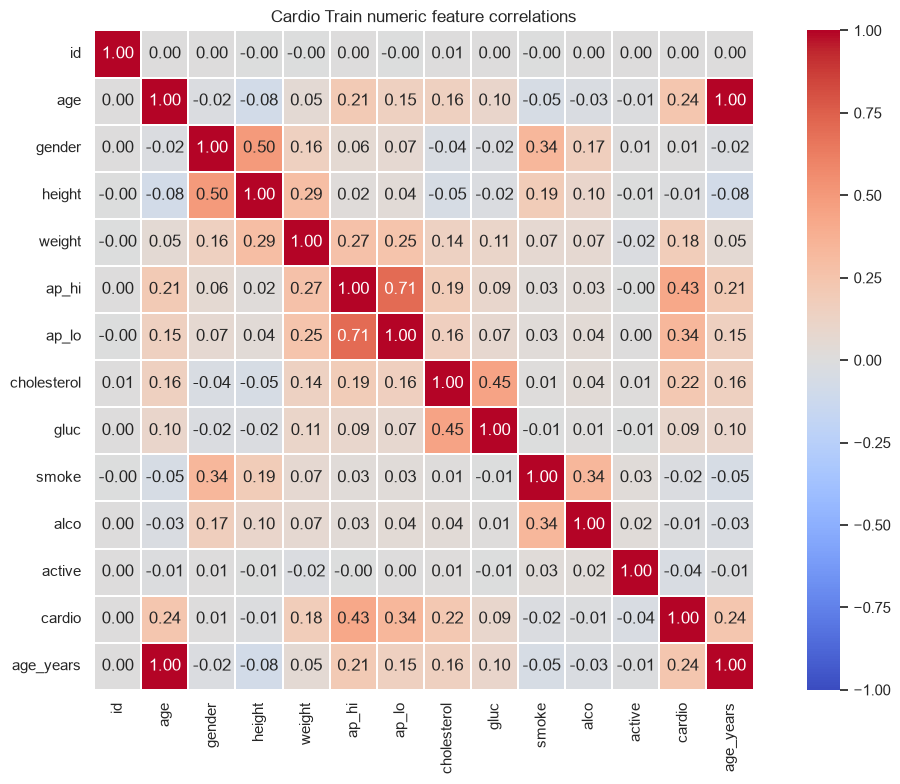

Saved C:\Users\kunug\OneDrive\Desktop\cardioVision\result\02_cardio_train_correlation_heatmap.png


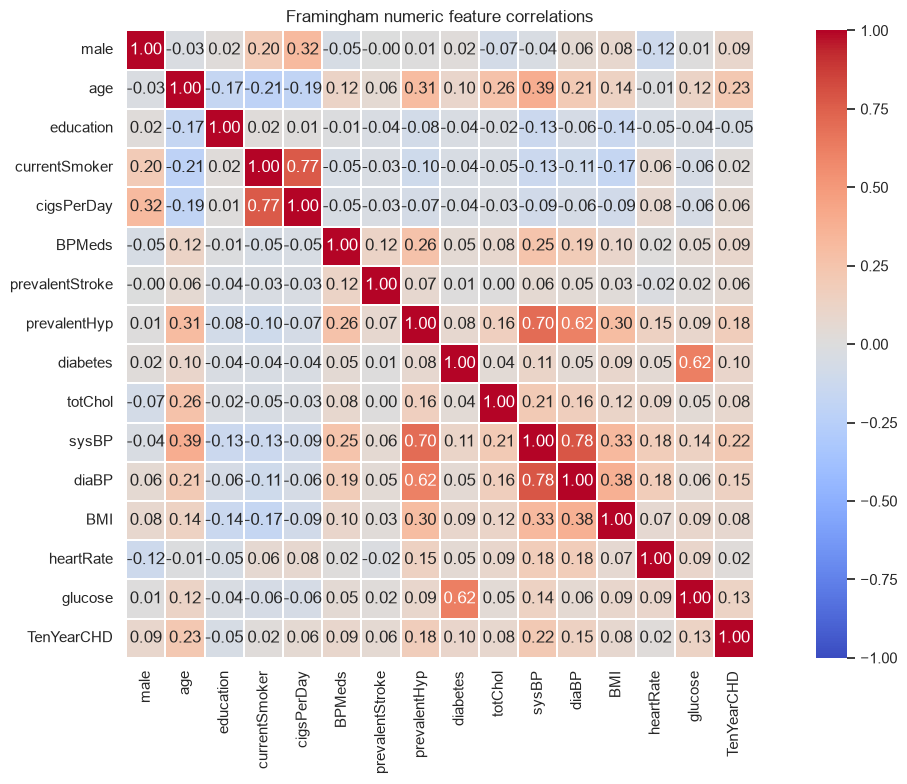

Saved C:\Users\kunug\OneDrive\Desktop\cardioVision\result\02_framingham_correlation_heatmap.png


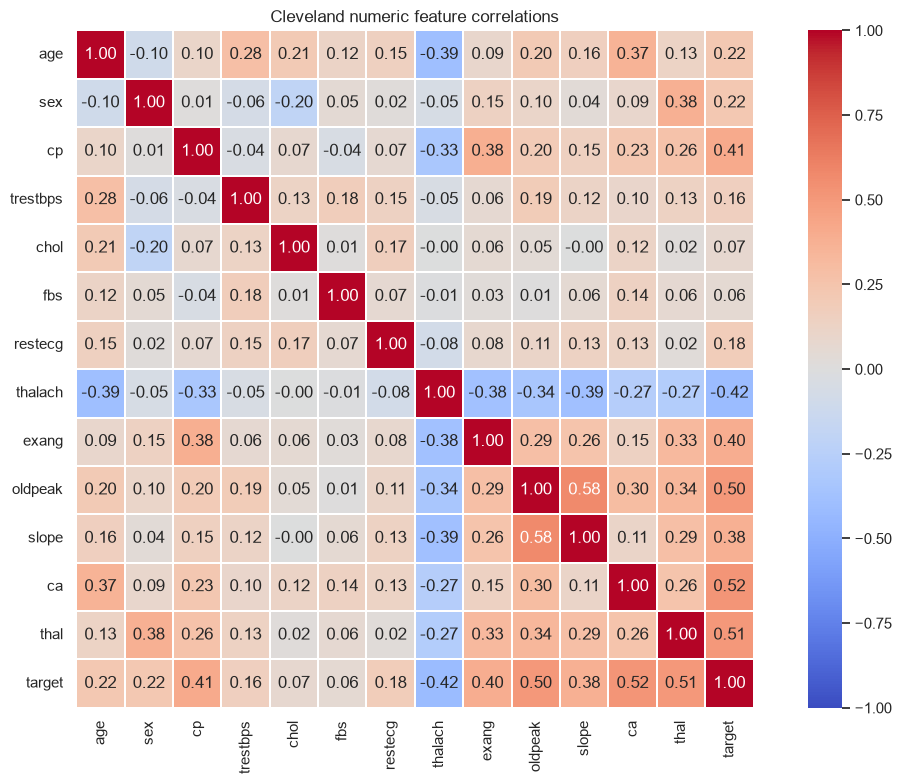

Saved C:\Users\kunug\OneDrive\Desktop\cardioVision\result\02_cleveland_correlation_heatmap.png


In [4]:
heatmap_frames = {
    "cardio_train": df_cardio_clean,
    "framingham": df_framingham,
    "cleveland": df_cleveland_clean,
}
for name, df in heatmap_frames.items():
    numeric = df.select_dtypes(include=np.number)
    correlation = numeric.corr()
    fig, ax = plt.subplots(figsize=(max(10, len(correlation.columns) * 0.8), 8))
    sns.heatmap(
        correlation, cmap="coolwarm", center=0, vmin=-1, vmax=1,
        annot=len(correlation.columns) <= 16, fmt=".2f", square=True,
        linewidths=0.3, ax=ax,
    )
    ax.set_title(f"{name.replace('_', ' ').title()} numeric feature correlations")
    fig.tight_layout()
    output_path = RESULT_DIR / f"02_{name}_correlation_heatmap.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved {output_path}")

## Cleaning and target summary

In [5]:
print("Cardio age_years summary:")
display(df_cardio_clean["age_years"].describe().to_frame())
print("Cardio target distribution after BP filtering:")
display(df_cardio_clean["cardio"].value_counts(normalize=False).sort_index().to_frame("count").assign(percent=lambda x: (100 * x["count"] / len(df_cardio_clean)).round(2)))
print("Framingham target distribution:")
display(df_framingham["TenYearCHD"].value_counts(normalize=False).sort_index().to_frame("count").assign(percent=lambda x: (100 * x["count"] / len(df_framingham)).round(2)))
print("Cleveland target distribution:")
display(df_cleveland_clean["target"].value_counts(normalize=False).sort_index().to_frame("count").assign(percent=lambda x: (100 * x["count"] / len(df_cleveland_clean)).round(2)))
print(f"Cleveland records preserved: {len(df_cleveland_clean):,}/{len(df_cleveland):,}; no target values were imputed.")

Cardio age_years summary:


,age_years
count,68761.000000
mean,52.790972
std,6.764574
min,29.000000
25%,48.000000
50%,53.000000
75%,58.000000
max,64.000000


Cardio target distribution after BP filtering:


,count,percent
cardio,,
0,34738,50.52
1,34023,49.48


Framingham target distribution:


,count,percent
TenYearCHD,,
0,3596,84.81
1,644,15.19


Cleveland target distribution:


,count,percent
target,,
0,164,54.13
1,55,18.15
2,36,11.88
3,35,11.55
4,13,4.29


Cleveland records preserved: 303/303; no target values were imputed.
